In [8]:
import pandas as pd
print(pd.__version__)


3.0.6


In [9]:
import numpy as np
print(np.__version__)
import matplotlib.pyplot as plt

2.5.4


In [10]:
df = pd.read_csv("../data/raw/journal_entries_4203.csv", sep=";")
df.head() # shows the first five lines of the document

,posting_id,document_date,posting_date,entered_date,gl_account,gl_account_name,amount,cd_flag,user,tax_rate,ref_id,text,promptly,weekend,nwh,label,marking,top_n,high_cash
0,a_1,2023-05-31,2023-05-31,2023-06-01 11:52:40,3400,"Cost of merchandise, 19% input tax",112.42,D,David,0.19,0,Rake,1,0,0,0,0,0,0
1,a_1,2023-05-31,2023-05-31,2023-06-01 11:52:40,1576,"Deductible input tax, 19%",21.36,D,David,0.19,0,Rake,1,0,0,0,0,0,0
2,a_1,2023-05-31,2023-05-31,2023-06-01 11:52:40,1600,Trade payables,133.78,C,David,0.19,0,Rake,1,0,0,0,0,0,0
3,a_2,2023-01-26,2023-01-26,2023-02-02 16:21:22,3400,"Cost of merchandise, 19% input tax",934.00,D,Bob,0.19,0,Lawn Mower,1,0,0,0,0,0,0
4,a_2,2023-01-26,2023-01-26,2023-02-02 16:21:22,1576,"Deductible input tax, 19%",177.46,D,Bob,0.19,0,Lawn Mower,1,0,0,0,0,0,0


In [11]:
df.info() #Ver informação sobre o dataset

<class 'pandas.DataFrame'>
RangeIndex: 256232 entries, 0 to 256231
Data columns (total 19 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   posting_id       256232 non-null  str    
 1   document_date    256232 non-null  str    
 2   posting_date     256232 non-null  str    
 3   entered_date     256232 non-null  str    
 4   gl_account       256232 non-null  int64  
 5   gl_account_name  256232 non-null  str    
 6   amount           256232 non-null  float64
 7   cd_flag          256232 non-null  str    
 8   user             256232 non-null  str    
 9   tax_rate         256232 non-null  float64
 10  ref_id           256232 non-null  str    
 11  text             256232 non-null  str    
 12  promptly         256232 non-null  int64  
 13  weekend          256232 non-null  int64  
 14  nwh              256232 non-null  int64  
 15  label            256232 non-null  int64  
 16  marking          256232 non-null  int64  
 17  to

In [12]:
df["posting_date"].head()

0    2023-05-31
1    2023-05-31
2    2023-05-31
3    2023-01-26
4    2023-01-26
Name: posting_date, dtype: str

In [13]:
df["document_date"] = pd.to_datetime(df["document_date"])
df["posting_date"] = pd.to_datetime(df["posting_date"])
df["entered_date"] = pd.to_datetime(df["entered_date"])

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 256232 entries, 0 to 256231
Data columns (total 19 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   posting_id       256232 non-null  str           
 1   document_date    256232 non-null  datetime64[us]
 2   posting_date     256232 non-null  datetime64[us]
 3   entered_date     256232 non-null  datetime64[us]
 4   gl_account       256232 non-null  int64         
 5   gl_account_name  256232 non-null  str           
 6   amount           256232 non-null  float64       
 7   cd_flag          256232 non-null  str           
 8   user             256232 non-null  str           
 9   tax_rate         256232 non-null  float64       
 10  ref_id           256232 non-null  str           
 11  text             256232 non-null  str           
 12  promptly         256232 non-null  int64         
 13  weekend          256232 non-null  int64         
 14  nwh              256232 non-nul

In [15]:
df["posting_date"].min()

Timestamp('2023-01-02 00:00:00')

In [16]:
df["posting_date"].max()

Timestamp('2024-12-30 00:00:00')

In [17]:
df.dtypes # Mostra o tipo de dados de cada coluna do csv

posting_id                    str
document_date      datetime64[us]
posting_date       datetime64[us]
entered_date       datetime64[us]
gl_account                  int64
gl_account_name               str
amount                    float64
cd_flag                       str
user                          str
tax_rate                  float64
ref_id                        str
text                          str
promptly                    int64
weekend                     int64
nwh                         int64
label                       int64
marking                     int64
top_n                       int64
high_cash                   int64
dtype: object

In [18]:
print("Linhas:", len(df)) # Número de linhas da tabela
print("Lançamentos:", df["posting_id"].nunique()) # Vai à coluna posting_id e conta quantos valores unicos existem, unique mostrava os valores diferentes
print("Contas:", df["gl_account"].nunique())
print("Users:", df["user"].nunique())

Linhas: 256232
Lançamentos: 102429
Contas: 25
Users: 6


In [19]:
df["cd_flag"].value_counts() #Vai contar quantas vezes aparece cada valor

cd_flag
D    135743
C    120489
Name: count, dtype: int64

In [20]:
df["signed_amount"] = np.where(df["cd_flag"] == "D", df["amount"], -df["amount"])
df[["posting_id", "cd_flag", "amount", "signed_amount"]].head()

,posting_id,cd_flag,amount,signed_amount
0,a_1,D,112.42,112.42
1,a_1,D,21.36,21.36
2,a_1,C,133.78,-133.78
3,a_2,D,934.00,934.00
4,a_2,D,177.46,177.46


In [21]:
filtro = df["posting_id"] == "a_1"
print(df[filtro][["posting_id", "cd_flag", "amount", "signed_amount"]])
print("Sum:", df[filtro]["signed_amount"].sum())

  posting_id cd_flag  amount  signed_amount
0        a_1       D  112.42         112.42
1        a_1       D   21.36          21.36
2        a_1       C  133.78        -133.78
Sum: 0.0


In [22]:
totais = df.groupby("posting_id")["signed_amount"].sum()
totais.head()


posting_id
a_1        0.0
a_10       0.0
a_100      0.0
a_1000     0.0
a_10000    0.0
Name: signed_amount, dtype: float64

In [23]:
filtro = df["posting_id"] == "p_2"
print("Linhas:", filtro.sum())
print(df[filtro][["posting_id", "gl_account_name", "cd_flag", "amount", "signed_amount"]])
print("Sum:", df[filtro]["signed_amount"].sum())

Linhas: 4
       posting_id            gl_account_name cd_flag   amount  signed_amount
256224        p_2          Other liabilities       D  1490.90        1490.90
256225        p_2      Prior-period expenses       D    63.36          63.36
256226        p_2  Deductible input tax, 19%       D   295.31         295.31
256227        p_2             Trade payables       C  1849.57       -1849.57
Sum: 0.0


In [24]:
filtro_nao_zero = totais != 0

print("Lançamentos com total diferente de zero:", filtro_nao_zero.sum())

print(totais[filtro_nao_zero].head())

filtro_desequilibrados = totais.round(2) != 0

print("Lançamentos desequilibrados:", filtro_desequilibrados.sum())

Lançamentos com total diferente de zero: 19452
posting_id
a_1013   -2.273737e-13
a_1023    2.842171e-14
a_1029    2.842171e-14
a_1050    7.105427e-15
a_106     3.552714e-15
Name: signed_amount, dtype: float64
Lançamentos desequilibrados: 0


In [25]:
df["prefixo"] = df["posting_id"].str.split("_").str[0]
print(df[["posting_id", "prefixo"]].head())
print(df["prefixo"].value_counts())


  posting_id prefixo
0        a_1       a
1        a_1       a
2        a_1       a
3        a_2       a
4        a_2       a
prefixo
a     24982
aa    24872
d     20000
e     20000
ad    20000
ae    20000
b     19986
ab    19908
c     17500
ac    17422
f      9982
af     9976
g      7490
ag     7478
h      5000
ah     4990
i      2500
ai     2486
xa      734
x       731
r       180
p        15
Name: count, dtype: int64


In [26]:
lancamentos_totais = df.groupby("prefixo")["posting_id"].nunique()
print(lancamentos_totais)

prefixo
a     9991
aa    9936
ab    7954
ac    6961
ad    8000
ae    8000
af    3988
ag    2989
ah    1995
ai     993
b     7993
c     7000
d     8000
e     8000
f     3991
g     2995
h     2000
i     1000
p        6
r       60
x      288
xa     289
Name: posting_id, dtype: int64


In [27]:
prefixo_a = df["prefixo"] == "a"
prefixo_aa = df["prefixo"] == "aa"

print(df[prefixo_a]["posting_date"].min())
print(df[prefixo_a]["posting_date"].max())

print(df[prefixo_aa]["posting_date"].min())
print(df[prefixo_aa]["posting_date"].max())


2023-01-02 00:00:00
2024-03-06 00:00:00
2024-01-01 00:00:00
2024-12-30 00:00:00


In [28]:
prefixo_c = df["prefixo"] == "c"

print(df[prefixo_a]["gl_account_name"].value_counts())
print(df[prefixo_c]["gl_account_name"].value_counts())

gl_account_name
Trade payables                        9975
Cost of merchandise, 19% input tax    5000
Deductible input tax, 19%             5000
Bank (Postbank)                       4966
Cash-in-hand                            29
Bank                                    12
Name: count, dtype: int64
gl_account_name
Trade receivables    7000
Revenue, 19%         3500
VAT, 19%             3500
Bank (Postbank)      3500
Name: count, dtype: int64


In [29]:
filtro_2024 = df["posting_date"] >= "2024-01-01"
print(df[prefixo_a & filtro_2024]["gl_account_name"].value_counts())

gl_account_name
Trade payables     93
Bank (Postbank)    90
Cash-in-hand        3
Name: count, dtype: int64


In [30]:
filtro_2023 = df["posting_date"] >= "2023-01-01"
filtro_ate2024 = df["posting_date"] <= "2023-12-31"     
print(df[prefixo_c & filtro_2023 & filtro_ate2024]["gl_account_name"].value_counts())
print(df[prefixo_c & filtro_2024]["gl_account_name"].value_counts())

gl_account_name
Trade receivables    6979
Revenue, 19%         3500
VAT, 19%             3500
Bank (Postbank)      3479
Name: count, dtype: int64
gl_account_name
Bank (Postbank)      21
Trade receivables    21
Name: count, dtype: int64


In [31]:
label_anomalia = df["label"] == 1
print(df[label_anomalia]["prefixo"].value_counts())

prefixo
a     211
g     207
f     204
ag    202
aa    194
af    190
ad    182
d     151
ah     77
h      56
c      51
e      49
i      47
ac     42
ae     38
ai     37
b      31
ab     27
x       7
xa      5
Name: count, dtype: int64


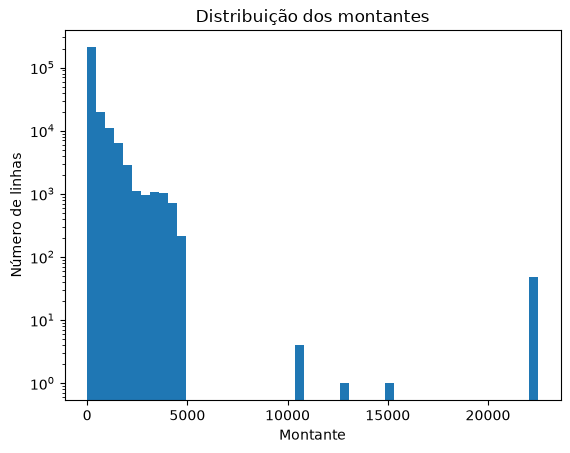

In [32]:
plt.hist(df["amount"], bins=50)
plt.title("Distribuição dos montantes")
plt.xlabel("Montante")
plt.ylabel("Número de linhas")
plt.yscale("log")
plt.show()

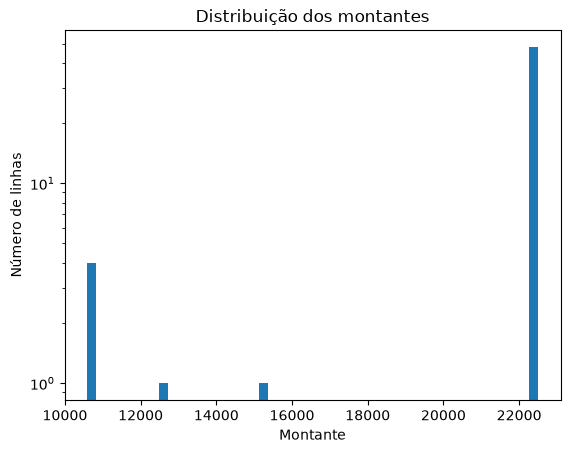

In [33]:
montante_acima_de_5000 = df["amount"] >= 5000

plt.hist(df[montante_acima_de_5000]["amount"], bins=50)
plt.title("Distribuição dos montantes")
plt.xlabel("Montante")
plt.ylabel("Número de linhas")
plt.yscale("log")
plt.show()


In [34]:
df[montante_acima_de_5000][["posting_id", "posting_date", "gl_account_name", "cd_flag", "amount", "text"]]


,posting_id,posting_date,gl_account_name,cd_flag,amount,text
127013,x_16,2023-01-05,Rent immovable property,D,22500.00,Rent January
127014,x_16,2023-01-05,Bank (Postbank),C,22500.00,Rent January
127076,x_41,2023-02-06,Rent immovable property,D,22500.00,Rent February
127077,x_41,2023-02-06,Bank (Postbank),C,22500.00,Rent February
127137,x_65,2023-03-03,Rent immovable property,D,22500.00,Rent March
127138,x_65,2023-03-03,Bank (Postbank),C,22500.00,Rent March
127198,x_89,2023-04-03,Rent immovable property,D,22500.00,Rent April
127199,x_89,2023-04-03,Bank (Postbank),C,22500.00,Rent April
127259,x_113,2023-05-03,Rent immovable property,D,22500.00,Rent May
127260,x_113,2023-05-03,Bank (Postbank),C,22500.00,Rent May


In [35]:
# 1. Lançamentos (não linhas) por utilizador
lancamentos_por_utilizador = df.groupby("user")["posting_id"].nunique()
print(lancamentos_por_utilizador)

# 2. Taxa de anomalias por utilizador, em percentagem
taxa_por_utilizador = df.groupby("user")["label"].mean() * 100
print(taxa_por_utilizador.round(2))



user
Alice      26175
Bob        32290
Charlie     6354
David      17802
Fred        6951
Max        12857
Name: posting_id, dtype: int64
user
Alice      0.06
Bob        0.07
Charlie    0.08
David      0.87
Fred       5.44
Max        1.78
Name: label, dtype: float64


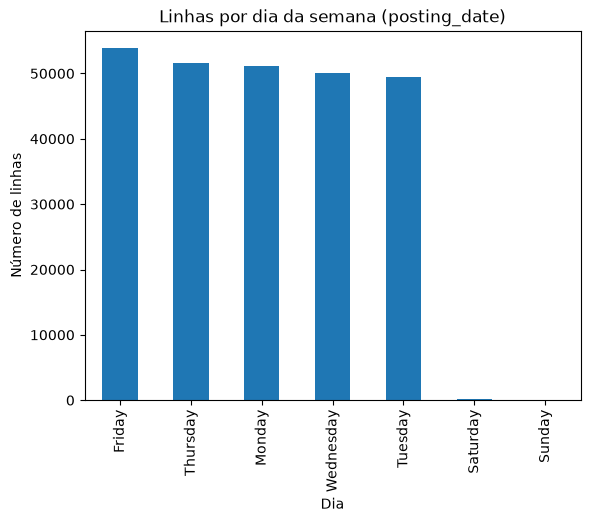

In [36]:
# Cria uma coluna nova com o nome do dia da semana da data contabilística
df["dia_contabilistico"] = df["posting_date"].dt.day_name()

# Conta as linhas por dia (ordena do maior para o menor, não por segunda-terça-…)
linhas_por_dia = df["dia_contabilistico"].value_counts()
linhas_por_dia.plot(kind="bar")
plt.title("Linhas por dia da semana (posting_date)")
plt.xlabel("Dia")
plt.ylabel("Número de linhas")
plt.show()


In [37]:
import duckdb

In [38]:
duckdb.sql("Select * FROM df LIMIT 5")

┌────────────┬─────────────────────┬─────────────────────┬─────────────────────┬────────────┬────────────────────────────────────┬────────┬─────────┬─────────┬──────────┬─────────┬────────────┬──────────┬─────────┬───────┬───────┬─────────┬───────┬───────────┬───────────────┬─────────┬────────────────────┐
│ posting_id │    document_date    │    posting_date     │    entered_date     │ gl_account │          gl_account_name           │ amount │ cd_flag │  user   │ tax_rate │ ref_id  │    text    │ promptly │ weekend │  nwh  │ label │ marking │ top_n │ high_cash │ signed_amount │ prefixo │ dia_contabilistico │
│  varchar   │      timestamp      │      timestamp      │      timestamp      │   int64    │              varchar               │ double │ varchar │ varchar │  double  │ varchar │  varchar   │  int64   │  int64  │ int64 │ int64 │  int64  │ int64 │   int64   │    double     │ varchar │      varchar       │
├────────────┼─────────────────────┼─────────────────────┼──────────────────

In [39]:
duckdb.sql(
    """
    SELECT posting_id, gl_account_name, cd_flag, amount
    FROM df
    WHERE posting_id = 'a_1'
    """
)

┌────────────┬────────────────────────────────────┬─────────┬────────┐
│ posting_id │          gl_account_name           │ cd_flag │ amount │
│  varchar   │              varchar               │ varchar │ double │
├────────────┼────────────────────────────────────┼─────────┼────────┤
│ a_1        │ Cost of merchandise, 19% input tax │ D       │ 112.42 │
│ a_1        │ Deductible input tax, 19%          │ D       │  21.36 │
│ a_1        │ Trade payables                     │ C       │ 133.78 │
└────────────┴────────────────────────────────────┴─────────┴────────┘

In [ ]:
duckdb.sql(
    """
    SELECT 
        COUNT(*) AS linhas,
        COUNT(DISTINCT posting_id) AS lancamentos
    FROM df    
    """
)

┌────────┬─────────────┐
│ linhas │ lancamentos │
│ int64  │    int64    │
├────────┼─────────────┤
│ 256232 │      102429 │
└────────┴─────────────┘

In [42]:
duckdb.sql(
    """
    SELECT
        user,
        COUNT(DISTINCT posting_id) AS lancamentos,
        ROUND(AVG(label) * 100, 2) AS taxa_anomalias
    FROM df
    GROUP BY user
    ORDER BY taxa_anomalias DESC
    """
)

┌─────────┬─────────────┬────────────────┐
│  user   │ lancamentos │ taxa_anomalias │
│ varchar │    int64    │     double     │
├─────────┼─────────────┼────────────────┤
│ Fred    │        6951 │           5.44 │
│ Max     │       12857 │           1.78 │
│ David   │       17802 │           0.87 │
│ Charlie │        6354 │           0.08 │
│ Bob     │       32290 │           0.07 │
│ Alice   │       26175 │           0.06 │
└─────────┴─────────────┴────────────────┘

In [43]:
duckdb.sql(
    """
    SELECT
        dayname(entered_date) AS dia_registo,
        COUNT(*) AS linhas,
        ROUND(AVG(label) * 100, 2) AS taxa_anomalias
    FROM df
    GROUP BY dia_registo
    ORDER BY taxa_anomalias DESC
    """
)

┌─────────────┬────────┬────────────────┐
│ dia_registo │ linhas │ taxa_anomalias │
│   varchar   │ int64  │     double     │
├─────────────┼────────┼────────────────┤
│ Sunday      │  16551 │           2.14 │
│ Saturday    │  14986 │           1.95 │
│ Friday      │  45317 │           0.85 │
│ Monday      │  46811 │            0.7 │
│ Wednesday   │  42781 │           0.59 │
│ Tuesday     │  45172 │           0.47 │
│ Thursday    │  44614 │           0.43 │
└─────────────┴────────┴────────────────┘

In [47]:
duckdb.sql(
    """
    SELECT
        COUNT(*) AS linhas,
        SUM(label) AS anomalias
    FROM df
    """
)

┌────────┬───────────┐
│ linhas │ anomalias │
│ int64  │  int128   │
├────────┼───────────┤
│ 256232 │      2008 │
└────────┴───────────┘

In [49]:
duckdb.sql(
    """
        SELECT
            COUNT(*) AS linhas,
            SUM(label) AS anomalias
        FROM df
        WHERE dayname(entered_date) = 'Saturday' OR dayname(entered_date) = 'Sunday' 
        """
)

┌────────┬───────────┐
│ linhas │ anomalias │
│ int64  │  int128   │
├────────┼───────────┤
│  31537 │       646 │
└────────┴───────────┘